# Tutorial 05

Assistant: [Alp Eren SARI](mailto:alp.sari@inf.unibe.ch)

## Last Week
*    Implement a 4 class classifier neural network on Pytorch

## This Week
*    Use regularization techniques to prevent overfitting


## Overfitting

<img src="https://drive.google.com/uc?export=view&id=1oukoUDdY1Tw97K3Vw2oJidhQhFNfnpsV" width="500" />

Underfitting: model is too simple to get good
results

<img src="https://drive.google.com/uc?export=view&id=1zakJsbJltssLAhyaYeYcq2LvheG6iRF8" width="500" />

Overfitting: Model is too complex for our dataset
*    memorizes training examples
*    doesn’t generalize to new data

## How to deal with overfitting?

*    We want to use complex models that can learn better representations
*    We can use regularization to reduce overfitting

## Regularization

Option 1: Get more data => expensive & difficult  <br>
generate more data => **data augmentation**

Option 2: Constrain your model <br>
Make it more difficult to memorize data => **L2 regularization, Dropout, Early stopping**

### Data Augmentation

<img src="https://way2vat.com/wp-content/uploads/2018/08/cat_augment.png" width="700" />

They are all cat, in fact; they all the same cat

#### Be Careful 
<img src="https://drive.google.com/uc?export=view&id=1LljG4XTSH6RBRSD17IaX_Ror-7lg_kqX" width="700" />

### Data Augmentation - Pytorch
Many of the data augmentation methods implemented in Pytorch's [torchvision / transform package](https://pytorch.org/vision/stable/transforms.html)





In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import torch
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import PIL
import requests

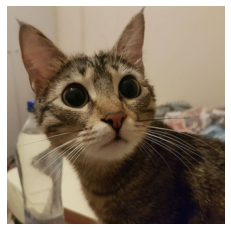

In [4]:
_img_url = "https://drive.google.com/uc?export=view&id=1WjH7avUYEOK3SPLYviG2F0IJhUTE6Yt4"
image = PIL.Image.open(requests.get(_img_url, stream=True).raw)
image = image.resize((320, 320))
plt.imshow(image)
plt.axis('off');

### Horizontal Flip

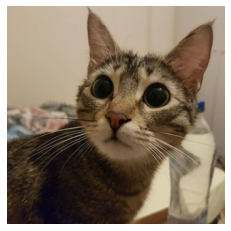

In [5]:
transform = transforms.RandomHorizontalFlip(p=1.0)
transformed = transform(image) # Transformations work on PIL images
plt.imshow(transformed)
plt.axis('off');

### Random Crop

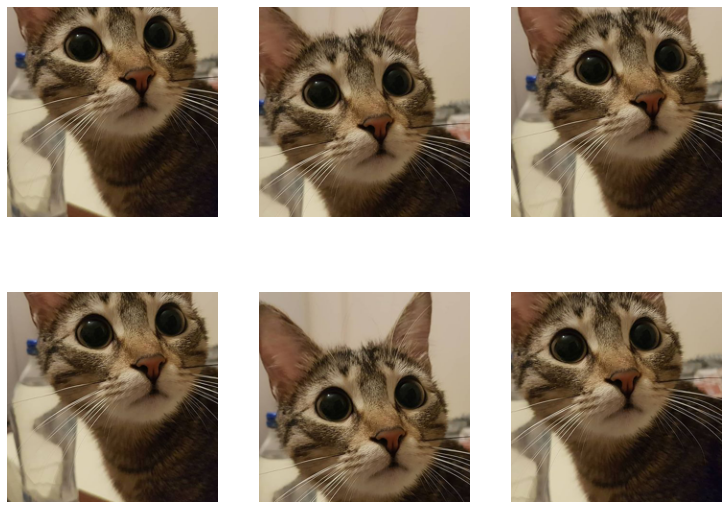

In [6]:
transform = transforms.RandomCrop((220, 220))
f, axes = plt.subplots(2, 3, figsize=(12.8, 9.6))
axes = [ax for axs in axes for ax in axs]
for i in range(6):
    transformed = transform(image)
    axes[i].imshow(transformed)
    axes[i].axis('off')

# Five Crop

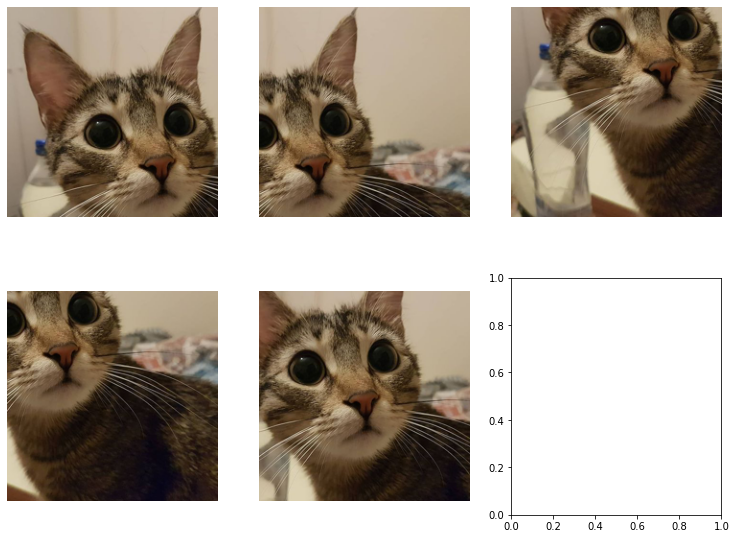

In [7]:
transform = transforms.FiveCrop((220, 220))
f, axes = plt.subplots(2, 3, figsize=(12.8, 9.6))
axes = [ax for axs in axes for ax in axs]
transformed = transform(image)
for i in range(5):
    axes[i].imshow(transformed[i])
    axes[i].axis('off')

# Color Jitter

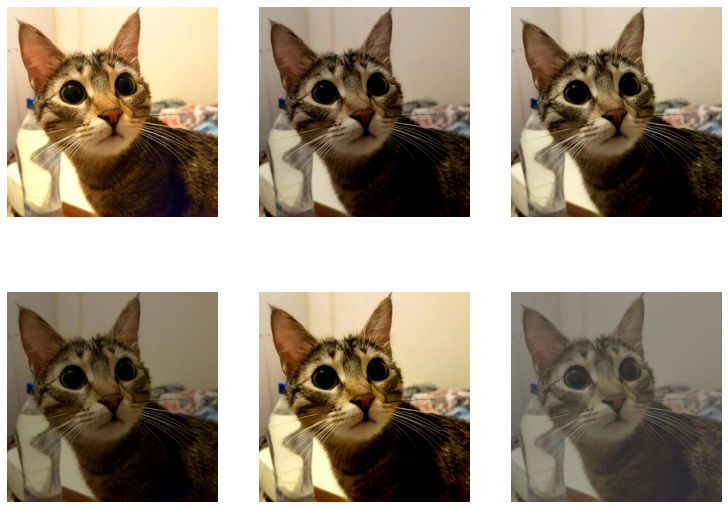

In [10]:
transform = transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.02)

f, axes = plt.subplots(2, 3, figsize=(12.8, 9.6))
axes = [ax for axs in axes for ax in axs]
for i in range(6):
    transformed = transform(image)
    axes[i].imshow(transformed)
    axes[i].axis('off')

# Random Resized Crop

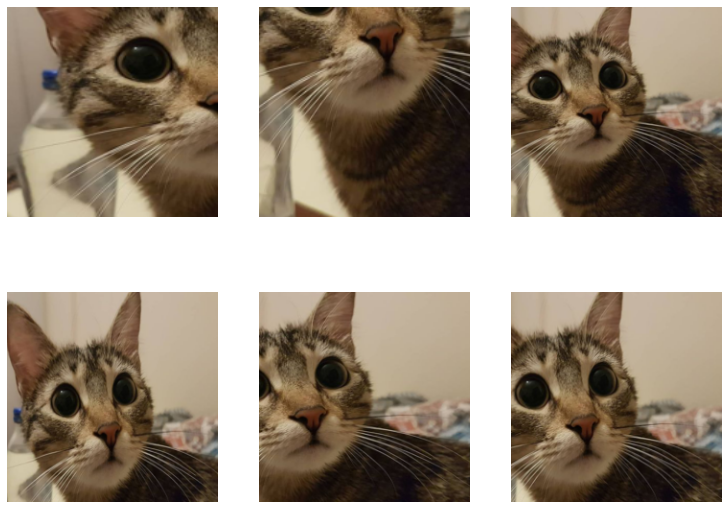

In [11]:
transform = transforms.RandomResizedCrop(220, scale=(0.2, 1.0), ratio=(0.75, 1.333))

f, axes = plt.subplots(2, 3, figsize=(12.8, 9.6))
axes = [ax for axs in axes for ax in axs]
for i in range(6):
    transformed = transform(image)
    axes[i].imshow(transformed)
    axes[i].axis('off')

# Random rotation

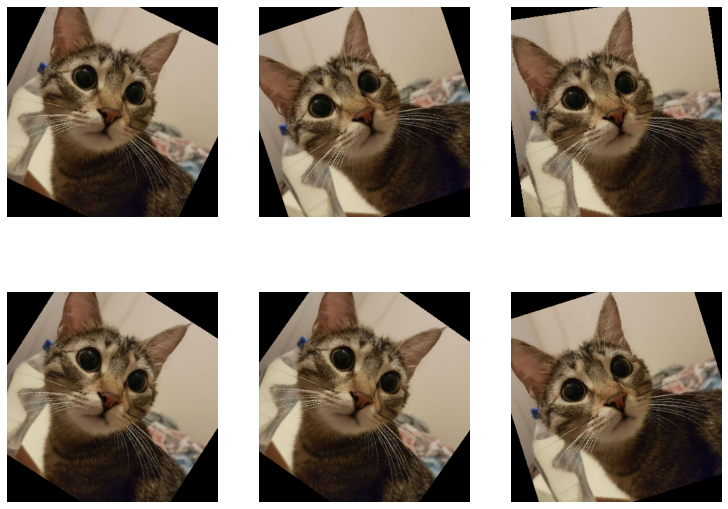

In [12]:
transform = transforms.RandomRotation(45)

f, axes = plt.subplots(2, 3, figsize=(12.8, 9.6))
axes = [ax for axs in axes for ax in axs]
for i in range(6):
    transformed = transform(image)
    axes[i].imshow(transformed)
    axes[i].axis('off')

# Random affine transform

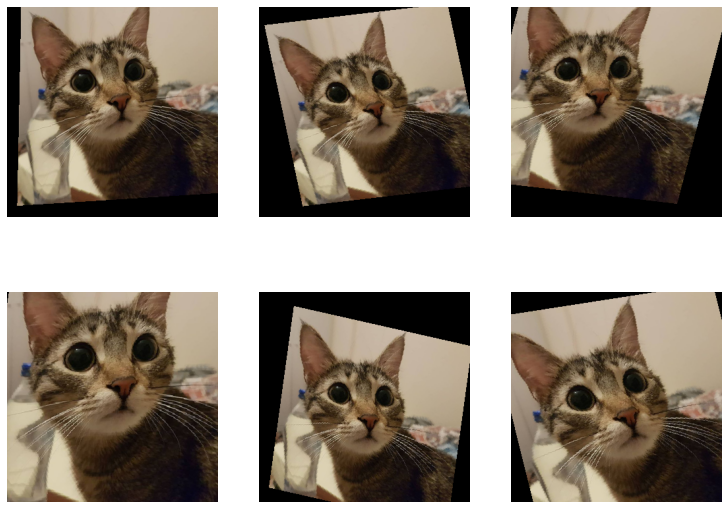

In [13]:
transform = transforms.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.8, 1.3), shear=10)

f, axes = plt.subplots(2, 3, figsize=(12.8, 9.6))
axes = [ax for axs in axes for ax in axs]
for i in range(6):
    transformed = transform(image)
    axes[i].imshow(transformed)
    axes[i].axis('off')

# Composition of transforms

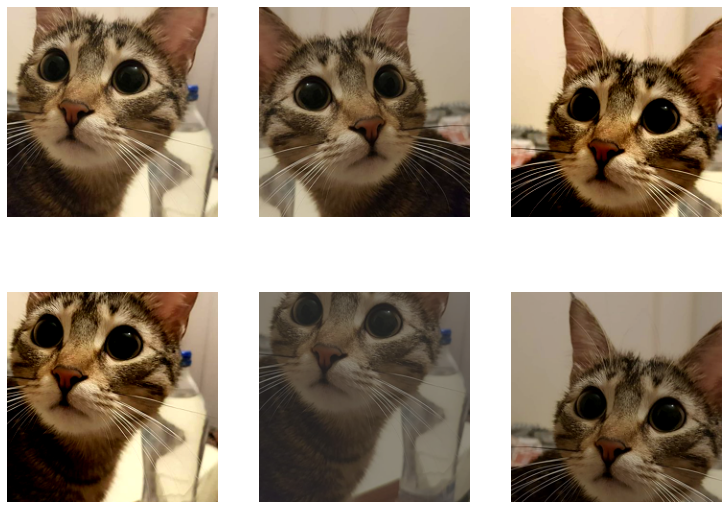

In [15]:
transform = transforms.Compose([
                    transforms.RandomCrop((220, 220)),
                    transforms.RandomHorizontalFlip(),
                    transforms.ColorJitter(0.2, 0.6)
            ])

f, axes = plt.subplots(2, 3, figsize=(12.8, 9.6))
axes = [ax for axs in axes for ax in axs]
for i in range(6):
    transformed = transform(image)
    axes[i].imshow(transformed)
    axes[i].axis('off')

## Early Stopping

Monitor validation loss / accuracy, save the model with the best value

<img src="https://drive.google.com/uc?export=view&id=1VtJVgRE4zxVmIQLkgQbLieDLQdsb8g0q" width="500" />

Green is better than red, so take the model from green. Stop the training at the place where validation loss starts increasing. 

<pre>
best_val_loss = np.inf
best_model = None
patience = 5 # if no improvement after 5 epochs, stop training
counter = 0
for epoch in range(n_epochs):
    ### Train for an epoch and evaluate on validation set
    ### (...)<b>
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model = deepcopy(model)
        counter = 0 </b>
    else:
        counter += 1
    if counter == patience:
        print('No improvement for {} epochs training stopped.'.format(patience))
        break
</pre>

## L2 Regularization / weight decay
By adding a new term to the loss function, constrain the weights. For example,
$$ L_{final} = L_{cross \ entropy} + \alpha L_{L2 \ regularization} $$
$$ L_{L2 \ regularization} = \frac{1}{2}\sum_{i}\theta_{i}^{2} $$ 
$$ \theta := network \ weights $$
$$ \alpha := regularization \ strength $$

## Dropout

<img src="https://miro.medium.com/max/2896/1*_8fQOrl8qYyHkr5vOQxxNA.png" width="700" />

*    Set hidden layer outputs to zero in **each iteration randomly; for training**
*    Use all the outputs (do nothing) **for evaluation**

In PyTorch - simply add `nn.Dropout()` layers in model definition. For example,
<pre>
class MLPModelDropout(nn.Module):
    def __init__(self, input_dim, hidden_dim, dropout_p=0.5):
    # dropout_p: probability of setting a unit to 0
    super(MLPModelDropout, self).__init__()
    self.layers = nn.Sequential(
        nn.Linear(input_dim, hidden_dim),
        nn.ReLU(),
        nn.Dropout(dropout_p), ### Adding dropout layer
        nn.Linear(hidden_dim, hidden_dim),
        nn.ReLU(),
        nn.Dropout(dropout_p), ### Adding dropout layer
        nn.Linear(hidden_dim, hidden_dim),
        nn.ReLU(),
        nn.Dropout(dropout_p), ### Adding dropout layer
        nn.Linear(hidden_dim, 2)
    )
    def forward(self, input):
      input = input.view(input.size(0), -1)
      return self.layers(input)
      
</pre>

Do not forget to set the model to train and eval modes by using
<pre>
model = MLPModelDropout(32*32*3, 128, 0.5)
model.train() # Sets all the layers to training mode - dropout is active
model.eval() # Seta all the layers to evaluation mode - dropout is inactive (does nothing)
</pre>


# Download the Dataset
We are using cats vs. dogs dataset used in Tutorial 01 and 03. You may download it from [here](https://www.floydhub.com/swaroopgrs/datasets/dogscats) and extract it to your working folder. Alternatively, you can just run the cell below to download and extract it. If you are not running the notebook on Google Colab, make sure that you have gdown by using the command `pip install gdown`. If you are on Windows, the cell won't work. You need to download and extraact the data from the link. 

In [1]:
!gdown --id 1sKjxoH-MQl3CBVEm6C0EHwV3rqtXOqWq
!mkdir dogscats
!tar -C dogscats/ -xf swaroopgrs-datasets-dogscats-1.tar

Downloading...
From: https://drive.google.com/uc?id=1sKjxoH-MQl3CBVEm6C0EHwV3rqtXOqWq
To: /content/swaroopgrs-datasets-dogscats-1.tar
887MB [00:11, 79.8MB/s]


In [2]:
from tqdm.notebook import tqdm
import numpy as np
import torch
import PIL
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("We are using {}".format(device))

We are using cuda


In [3]:
from torchvision.datasets import ImageFolder
from torchvision.transforms import Resize, ToTensor, Normalize, Compose
root_dir = 'dogscats/train'

target_size = (32, 32)
transforms = Compose([Resize(target_size), # Resizes image
                    ToTensor(),           # Converts to Tensor, scales to [0, 1] float (from [0, 255] int)
                    Normalize(mean=(0.5, 0.5, 0.5,), std=(0.5, 0.5, 0.5)), # scales to [-1.0, 1.0]
                    ])

train_dataset_ = ImageFolder(root_dir, transform=Resize((40,40)))

In [4]:
print(len(train_dataset_))

23000


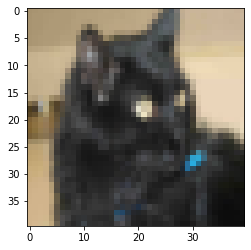

In [5]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.imshow(train_dataset_[101][0])

In [6]:
class RAMDatasetWrapper(torch.utils.data.Dataset):
    def __init__(self, dataset, transform=None):
        data = []
        for sample in tqdm(dataset):
            data.append(sample)
        self.n = len(dataset)
        self.data = data
        self.transform = transform
        
    def __getitem__(self, ind):
        if self.transform is not None:
            return self.transform(self.data[ind][0]), self.data[ind][1]
        else:
            return self.data[ind]
    
    def set_tranform(self, transform):
        self.transform = transform
    
    def __len__(self):
        return self.n

In [7]:
train_dataset = RAMDatasetWrapper(train_dataset_, transform=transforms)

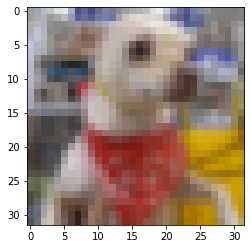

In [8]:
%matplotlib inline
import matplotlib.pyplot as plt
idx = np.random.randint(0, len(train_dataset), )
plt.imshow((train_dataset[idx][0]*0.5+0.5).numpy().transpose(1, 2, 0))

In [9]:
from torch.utils.data import DataLoader
batch_size = 64
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)

In [10]:
# Same for validation dataset
val_root_dir = 'dogscats/valid'
val_dataset_ = ImageFolder(val_root_dir, transform=None)
val_dataset = RAMDatasetWrapper(val_dataset_, transform=transforms)
val_dataloader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

In [11]:
print(len(val_dataset))

2000


In [12]:
import torch.nn as nn
    
class MLPModel(nn.Module):
    
    def __init__(self, input_dim, hidden_dim):
        super(MLPModel, self).__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2)
        )
    
    def forward(self, input):
        input = input.view(input.size(0), -1)
        return self.layers(input)

In [13]:
import numpy as np

def train_epoch(model, train_dataloader, optimizer, loss_fn):
    losses = []
    correct_predictions = 0
    # Iterate mini batches over training dataset
    for images, labels in tqdm(train_dataloader):
        images = images.to(device)
        labels = labels.to(device)
        # Run predictions
        output = model(images)
        # Set gradients to zero
        optimizer.zero_grad()
        # Compute loss
        loss = loss_fn(output, labels)
        # Backpropagate (compute gradients)
        loss.backward()
        # Make an optimization step (update parameters)
        optimizer.step()
        # Log metrics
        losses.append(loss.item())
        predicted_labels = output.argmax(dim=1)
        correct_predictions += (predicted_labels == labels).sum().item()
    accuracy = 100.0 * correct_predictions / len(train_dataloader.dataset)
    # Return loss values for each iteration and accuracy
    mean_loss = np.array(losses).mean()
    return mean_loss, accuracy

def evaluate(model, dataloader, loss_fn):
    losses = []
    correct_predictions = 0
    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)
            # Run predictions
            output = model(images)
            # Compute loss
            loss = loss_fn(output, labels)
            # Save metrics
            predicted_labels = output.argmax(dim=1)
            correct_predictions += (predicted_labels == labels).sum().item()
            losses.append(loss.item())
    mean_loss = np.array(losses).mean()
    accuracy = 100.0 * correct_predictions / len(dataloader.dataset)
    # Return mean loss and accuracy
    return mean_loss, accuracy

def train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_function):
    # We will monitor loss functions as the training progresses
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    for epoch in range(n_epochs):
        model.train()
        train_loss, train_accuracy = train_epoch(model, train_dataloader, optimizer, loss_fn)
        model.eval()
        val_loss, val_accuracy = evaluate(model, val_dataloader, loss_fn)
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_accuracy)
        val_accuracies.append(val_accuracy)
        print('Epoch {}/{}: train_loss: {:.4f}, train_accuracy: {:.4f}, val_loss: {:.4f}, val_accuracy: {:.4f}'.format(epoch+1, n_epochs,
                                                                                                      train_losses[-1],
                                                                                                      train_accuracies[-1],
                                                                                                      val_losses[-1],
                                                                                                      val_accuracies[-1]))
    return train_losses, val_losses, train_accuracies, val_accuracies

In [14]:
def plot(train_losses, val_losses, train_accuracies, val_accuracies, title):
    plt.figure()
    plt.plot(np.arange(len(train_losses)), train_losses)
    plt.plot(np.arange(len(val_losses)), val_losses)
    plt.legend(['train_loss', 'val_loss'])
    plt.xlabel('epoch')
    plt.ylabel('loss value')
    plt.title('{}: Train/val loss'.format(title));

    plt.figure()
    plt.plot(np.arange(len(train_accuracies)), train_accuracies)
    plt.plot(np.arange(len(val_accuracies)), val_accuracies)
    plt.legend(['train_acc', 'val_acc'])
    plt.xlabel('epoch')
    plt.ylabel('accuracy')
    plt.title('{}: Train/val accuracy'.format(title));

In [15]:
model = MLPModel(32*32*3, 128)
model = model.to(device)
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()

In [16]:
train_losses, val_losses, train_acc, val_acc = train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn)


Epoch 1/25: train_loss: 0.6585, train_accuracy: 60.4696, val_loss: 0.6372, val_accuracy: 63.0500



Epoch 2/25: train_loss: 0.6222, train_accuracy: 65.1304, val_loss: 0.6327, val_accuracy: 62.8500



Epoch 3/25: train_loss: 0.6002, train_accuracy: 67.2783, val_loss: 0.6238, val_accuracy: 64.6500



Epoch 4/25: train_loss: 0.5845, train_accuracy: 68.6174, val_loss: 0.6045, val_accuracy: 66.1000



Epoch 5/25: train_loss: 0.5682, train_accuracy: 69.9000, val_loss: 0.6241, val_accuracy: 64.7000


...


Epoch 21/25: train_loss: 0.2979, train_accuracy: 86.9522, val_loss: 0.9566, val_accuracy: 65.1000



Epoch 22/25: train_loss: 0.2830, train_accuracy: 87.3174, val_loss: 0.8633, val_accuracy: 65.2500



Epoch 23/25: train_loss: 0.2659, train_accuracy: 88.4391, val_loss: 1.0191, val_accuracy: 66.9000



Epoch 24/25: train_loss: 0.2504, train_accuracy: 89.0478, val_loss: 1.3920, val_accuracy: 61.2000



Epoch 25/25: train_loss: 0.2428, train_accuracy: 89.5261, val_loss: 1.1210, val_accuracy: 65.6000


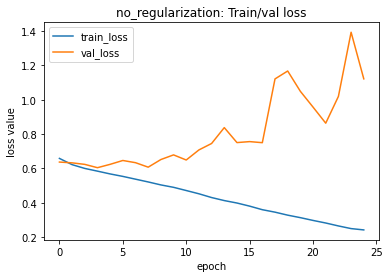

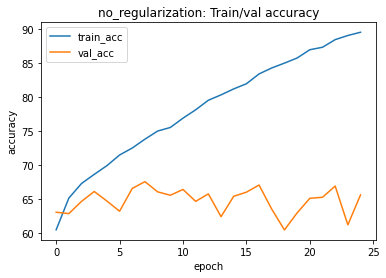

In [17]:
plot(train_losses, val_losses, train_acc, val_acc, title='no_regularization')

In [18]:
val_accuracy_no_regularization = val_acc[-1]
val_loss_no_regularization = val_losses[-1]
print('No regularization. Validation loss: {:.4f}, validation accuracy: {:.4f}'.format(val_loss_no_regularization, val_accuracy_no_regularization))

No regularization. Validation loss: 1.1210, validation accuracy: 65.6000


# Early stopping
We will monitor **val_loss** and save the model with the lowest value.  
We could also stop the training if the validation loss stops decreasing

In [20]:
from copy import deepcopy

def train_early_stopping(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_function):
    # We will monitor loss functions as the training progresses
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    ### EARLY STOPPING INITIALIZATION
    best_val_loss = np.inf
    best_model = None
    patience = 5 # if no improvement after 5 epochs, stop training
    counter = 0
    ###

    for epoch in range(n_epochs):
        model.train()
        train_loss, train_accuracy = train_epoch(model, train_dataloader, optimizer, loss_fn)
        model.eval()
        val_loss, val_accuracy = evaluate(model, val_dataloader, loss_fn)
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_accuracy)
        val_accuracies.append(val_accuracy)
        print('Epoch {}/{}: train_loss: {:.4f}, train_accuracy: {:.4f}, val_loss: {:.4f}, val_accuracy: {:.4f}'.format(epoch+1, n_epochs,
                                                                                                      train_losses[-1],
                                                                                                      train_accuracies[-1],
                                                                                                      val_losses[-1],
                                                                                                      val_accuracies[-1]))
    
        ### EARLY STOPPING CODE
        if val_loss < best_val_loss: # If validation loss improved, save the model and reset the counter
            best_val_loss = val_loss
            best_model = deepcopy(model)
            counter = 0
        else: # If validation loss not improved, increase the counter
            counter += 1
        if counter == patience: # If no improvement for some number of epochs, stop training
            print('No improvement for {} epochs; training stopped.'.format(patience))
            break
    # Copy best model parameters to model
    for param1, param2 in zip(model.parameters(), best_model.parameters()):
        param1.data = param2.data
    ###
    return train_losses, val_losses, train_accuracies, val_accuracies

In [22]:
model = MLPModel(32*32*3, 64)
model = model.to(device)
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
n_epochs = 25
loss_function = nn.CrossEntropyLoss()

train_losses_es, val_losses_es, train_acc_es, val_acc_es = train_early_stopping(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn)


Epoch 1/25: train_loss: 0.6623, train_accuracy: 59.3696, val_loss: 0.6595, val_accuracy: 58.4500



Epoch 2/25: train_loss: 0.6263, train_accuracy: 64.3130, val_loss: 0.6284, val_accuracy: 63.9000



Epoch 3/25: train_loss: 0.6074, train_accuracy: 66.6087, val_loss: 0.6225, val_accuracy: 64.7500



Epoch 4/25: train_loss: 0.5918, train_accuracy: 67.9957, val_loss: 0.6410, val_accuracy: 64.4000



Epoch 5/25: train_loss: 0.5795, train_accuracy: 69.2261, val_loss: 0.6079, val_accuracy: 66.4000



Epoch 6/25: train_loss: 0.5665, train_accuracy: 70.1826, val_loss: 0.6374, val_accuracy: 65.9500



Epoch 7/25: train_loss: 0.5551, train_accuracy: 70.9000, val_loss: 0.6105, val_accuracy: 67.2000



Epoch 8/25: train_loss: 0.5438, train_accuracy: 71.8870, val_loss: 0.6230, val_accuracy: 66.7500



Epoch 9/25: train_loss: 0.5313, train_accuracy: 72.6913, val_loss: 0.6397, val_accuracy: 65.1000



Epoch 10/25: train_loss: 0.5208, train_accuracy: 73.8565, val_loss: 0.6168, val_accuracy: 65.3500
No improvement for 5 epochs; training stopped.


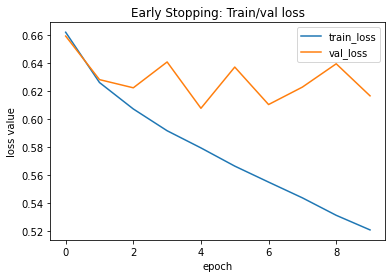

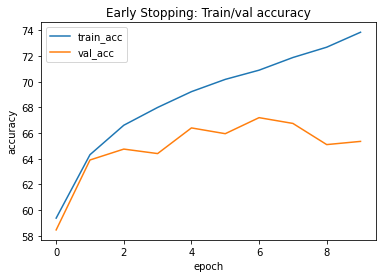

In [23]:
plot(train_losses_es, val_losses_es, train_acc_es, val_acc_es, title='Early Stopping')

In [24]:
# Evaluate on best model
val_loss_early_stopping, val_accuracy_early_stopping = evaluate(model, val_dataloader, loss_fn)
print('Early stopping. Validation loss: {:.4f}, validation accuracy: {:.4f}'.format(val_loss_early_stopping, val_accuracy_early_stopping))

Early stopping. Validation loss: 0.6079, validation accuracy: 66.4000


# Data augmentation
We will add several transformations that preserve the label (https://pytorch.org/docs/stable/torchvision/transforms.html#transforms-on-pil-image):
- Random horizontal flip
- Random crop (we will first resize to (40, 40), then take crops of size (32, 32))

In [26]:
# Let's modify 
from torchvision.transforms import Compose, Resize, RandomHorizontalFlip, RandomCrop, ToTensor, Normalize

transforms_da = Compose([
                        RandomCrop((32, 32)), # Crop 32x32 area
                        RandomHorizontalFlip(),   
                        ToTensor(),           # Converts to Tensor, scales to [0, 1] float (from [0, 255] int)
                        Normalize(mean=(0.5, 0.5, 0.5,), std=(0.5, 0.5, 0.5)), # scales to [-1.0, 1.0]
                    ])

train_dataset.set_tranform(transforms_da)
train_dataloader_augmented = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)

Train with augmented images

In [27]:
model = MLPModel(32*32*3, 128)
model = model.to(device)
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()

train_losses_da, val_losses_da, train_acc_da, val_acc_da = train(model, train_dataloader_augmented, val_dataloader, optimizer, n_epochs, loss_fn)


Epoch 1/25: train_loss: 0.6742, train_accuracy: 57.8391, val_loss: 0.6559, val_accuracy: 61.5000



Epoch 2/25: train_loss: 0.6516, train_accuracy: 61.2000, val_loss: 0.6405, val_accuracy: 63.1000



Epoch 3/25: train_loss: 0.6411, train_accuracy: 62.5478, val_loss: 0.6511, val_accuracy: 62.6500



Epoch 4/25: train_loss: 0.6342, train_accuracy: 63.3739, val_loss: 0.6264, val_accuracy: 63.9000



Epoch 5/25: train_loss: 0.6268, train_accuracy: 64.4565, val_loss: 0.6198, val_accuracy: 64.0500


...


Epoch 21/25: train_loss: 0.5840, train_accuracy: 68.6217, val_loss: 0.5865, val_accuracy: 68.3000



Epoch 22/25: train_loss: 0.5805, train_accuracy: 68.8478, val_loss: 0.5893, val_accuracy: 69.0500



Epoch 23/25: train_loss: 0.5817, train_accuracy: 68.7870, val_loss: 0.6035, val_accuracy: 68.3000



Epoch 24/25: train_loss: 0.5783, train_accuracy: 69.3304, val_loss: 0.5944, val_accuracy: 66.7500



Epoch 25/25: train_loss: 0.5740, train_accuracy: 69.2000, val_loss: 0.5828, val_accuracy: 69.2500


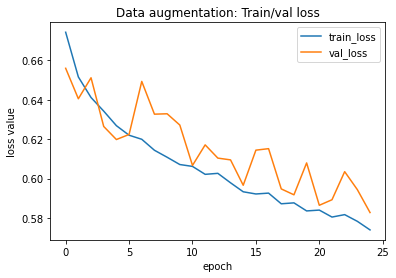

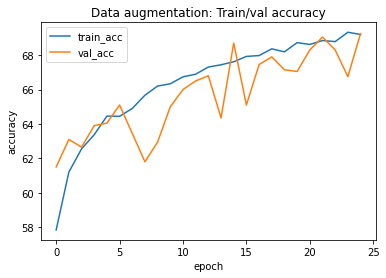

In [28]:
plot(train_losses_da, val_losses_da, train_acc_da, val_acc_da, title='Data augmentation')

In [29]:
val_loss_dataaugmentation, val_accuracy_dataaugmentation = val_losses_da[-1], val_acc_da[-1]
print('Data augmentation. Validation loss: {:.4f}, validation accuracy: {:.4f}'.format(val_loss_dataaugmentation, val_accuracy_dataaugmentation))

Data augmentation. Validation loss: 0.5828, validation accuracy: 69.2500


# L2 regularization / weight decay
We can specify strength of weight decay in optimizer (parameter of optimizer's constructor; https://pytorch.org/docs/stable/optim.html#torch.optim.SGD)

In [30]:
model = MLPModel(32*32*3, 128)
model = model.to(device)
learning_rate = 0.1
### L2 regularization code
alpha = 0.0075 # If too big - the network won't train at all (weights will be zero)
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, weight_decay=alpha)
### End
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()
train_dataset.set_tranform(transforms)

In [31]:
train_losses_wd, val_losses_wd, train_acc_wd, val_acc_wd = train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn)


Epoch 1/25: train_loss: 0.6623, train_accuracy: 60.0522, val_loss: 0.6438, val_accuracy: 62.1000



Epoch 2/25: train_loss: 0.6296, train_accuracy: 64.3478, val_loss: 0.6359, val_accuracy: 63.2500



Epoch 3/25: train_loss: 0.6157, train_accuracy: 65.7783, val_loss: 0.6235, val_accuracy: 64.4000



Epoch 4/25: train_loss: 0.6087, train_accuracy: 66.3348, val_loss: 0.6203, val_accuracy: 65.3000



Epoch 5/25: train_loss: 0.6031, train_accuracy: 67.1217, val_loss: 0.6189, val_accuracy: 66.1000


...


Epoch 21/25: train_loss: 0.5698, train_accuracy: 70.1348, val_loss: 0.6291, val_accuracy: 66.0500



Epoch 22/25: train_loss: 0.5699, train_accuracy: 69.9435, val_loss: 0.6141, val_accuracy: 66.0500



Epoch 23/25: train_loss: 0.5703, train_accuracy: 70.1652, val_loss: 0.6653, val_accuracy: 63.9000



Epoch 24/25: train_loss: 0.5674, train_accuracy: 70.4130, val_loss: 0.6533, val_accuracy: 64.8000



Epoch 25/25: train_loss: 0.5652, train_accuracy: 70.4174, val_loss: 0.6678, val_accuracy: 62.5000


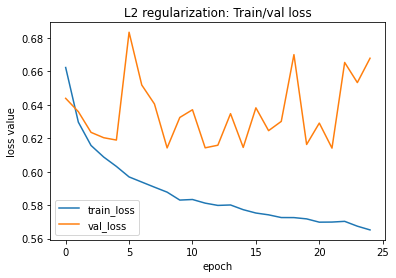

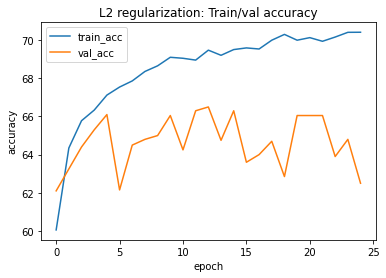

In [32]:
plot(train_losses_wd, val_losses_wd, train_acc_wd, val_acc_wd, title='L2 regularization')

In [33]:
val_loss_weightdecay, val_accuracy_weightdecay = val_losses_wd[-1], val_acc_wd[-1]
print('L2 regularization. Validation loss: {:.4f}, validation accuracy: {:.4f}'.format(val_loss_weightdecay, val_accuracy_weightdecay))

L2 regularization. Validation loss: 0.6678, validation accuracy: 62.5000


# Dropout
We will add dropout layers after every activation function.  
Dropout documentation: https://pytorch.org/docs/stable/nn.html#torch.nn.Dropout

In [34]:
import torch.nn as nn
    
class MLPModelDropout(nn.Module):
    
    def __init__(self, input_dim, hidden_dim, dropout_p=0.5):
        super(MLPModelDropout, self).__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout_p),  ### Adding dropout layer
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout_p),  ### Adding dropout layer
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout_p),  ### Adding dropout layer
            nn.Linear(hidden_dim, 2)
        )
    
    def forward(self, input):
        input = input.view(input.size(0), -1)
        return self.layers(input)

In [35]:
### MODEL WITH DROPOUT
dropout_p = 0.4
model = MLPModelDropout(32*32*3, 128, dropout_p=dropout_p)
### END
model = model.to(device)
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()

In [36]:
train_losses_dropout, val_losses_dropout, train_acc_dropout, val_acc_dropout = train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn)


Epoch 1/25: train_loss: 0.6717, train_accuracy: 57.9522, val_loss: 0.6469, val_accuracy: 61.6500



Epoch 2/25: train_loss: 0.6496, train_accuracy: 61.9870, val_loss: 0.6348, val_accuracy: 63.5500



Epoch 3/25: train_loss: 0.6365, train_accuracy: 63.5957, val_loss: 0.6393, val_accuracy: 59.8500



Epoch 4/25: train_loss: 0.6260, train_accuracy: 64.5913, val_loss: 0.6196, val_accuracy: 64.8500



Epoch 5/25: train_loss: 0.6201, train_accuracy: 65.5217, val_loss: 0.6139, val_accuracy: 66.6000


...


Epoch 21/25: train_loss: 0.5470, train_accuracy: 71.9913, val_loss: 0.5977, val_accuracy: 68.4500



Epoch 22/25: train_loss: 0.5437, train_accuracy: 72.1261, val_loss: 0.5927, val_accuracy: 68.1500



Epoch 23/25: train_loss: 0.5385, train_accuracy: 72.2957, val_loss: 0.5977, val_accuracy: 67.8000



Epoch 24/25: train_loss: 0.5308, train_accuracy: 72.9435, val_loss: 0.5951, val_accuracy: 67.4000



Epoch 25/25: train_loss: 0.5294, train_accuracy: 73.3217, val_loss: 0.5887, val_accuracy: 67.9500


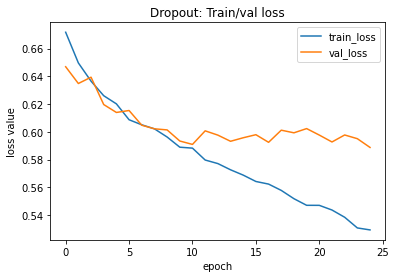

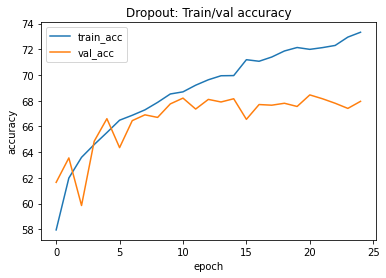

In [37]:
plot(train_losses_dropout, val_losses_dropout, train_acc_dropout, val_acc_dropout, title='Dropout')

In [39]:
val_loss_dropout, val_accuracy_dropout = val_losses_dropout[-1], val_acc_dropout[-1]
print('Dropout. Validation loss: {:.4f}, validation accuracy: {:.4f}'.format(val_loss_dropout, val_accuracy_dropout))

Dropout. Validation loss: 0.5887, validation accuracy: 67.9500


# Results comparison

In [40]:
table_data = [
    ['Regularization type', 'Val Loss', 'Val accuracy'],
    ['No regularization', val_loss_no_regularization, val_accuracy_no_regularization], 
    ['Early stopping', val_loss_early_stopping, val_accuracy_early_stopping],
    ['Data augmentation', val_loss_dataaugmentation, val_accuracy_dataaugmentation],
    ['L2 regularization', val_loss_weightdecay, val_accuracy_weightdecay],
    ['Dropout', val_loss_dropout, val_accuracy_dropout],
]
print("{: >20}| {: >20}| {: >20}".format(*table_data[0]))
print('-'.join(['' for i in range(65)]))
for row in table_data[1:]:
    print("{: >20}| {:20.4f}| {: >20}".format(*row))

 Regularization type|             Val Loss|         Val accuracy
----------------------------------------------------------------
   No regularization|               1.1210|                 65.6
      Early stopping|               0.6079|                 66.4
   Data augmentation|               0.5828|                69.25
   L2 regularization|               0.6678|                 62.5
             Dropout|               0.5887|                67.95


In [41]:
loss_curves = [val_losses, val_losses_es, val_losses_da, val_losses_wd, val_losses_dropout]
reg_types = ['no regularization', 'early stopping', 'data augmentation', 'l2 regularization', 'dropout']

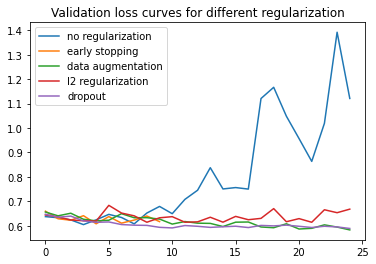

In [42]:
for loss_curve in loss_curves:
    plt.plot(np.arange(len(loss_curve)), loss_curve)
plt.title('Validation loss curves for different regularization')
plt.legend(reg_types);

**Usually we use more than one method for regularization (even all of the above)**